<a href="https://colab.research.google.com/github/Nafisatibrahim/Unsupervised-fraud-detection-the-outliers/blob/24-fill-in-notebooks02-edaipynb/02-eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!git clone https://github.com/Nafisatibrahim/Unsupervised-fraud-detection-the-outliers.git

Cloning into 'Unsupervised-fraud-detection-the-outliers'...
remote: Enumerating objects: 273, done.
remote: Counting objects: 100% (273/273), done.
remote: Compressing objects: 100% (177/177), done.
remote: Total 273 (delta 114), reused 207 (delta 72), pack-reused 0 (from 0)
Receiving objects: 100% (273/273), 3.91 MiB | 11.60 MiB/s, done.
Resolving deltas: 100% (114/114), done.


In [ ]:
%cd Unsupervised-fraud-detection-the-outliers

/content/Unsupervised-fraud-detection-the-outliers


In [ ]:
!pwd

/content/Unsupervised-fraud-detection-the-outliers


In [ ]:
!git checkout main

Already on 'main'
Your branch is up to date with 'origin/main'.


In [ ]:
!git checkout -b feature/eda

Switched to a new branch 'feature/eda'


In [ ]:
!git branch

* feature/eda
  main


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving features.parquet to features.parquet
Saving label.parquet to label.parquet


In [ ]:
import os

os.makedirs('data/cleaned', exist_ok=True)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import shutil

shutil.move('features.parquet', 'data/cleaned/features.parquet')
shutil.move('label.parquet', 'data/cleaned/label.parquet')

'data/cleaned/label.parquet'

In [ ]:
!ls data/cleaned

features.parquet  label.parquet


In [50]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

PROJECT_MARKERS = ('.git', 'requirements.txt')

def find_project_root(start_dir=None, markers=PROJECT_MARKERS):
    current = os.path.abspath(start_dir or os.getcwd())

    while True:
        if any(os.path.exists(os.path.join(current, marker)) for marker in markers):
            return current

        parent = os.path.dirname(current)

        if parent == current:
            raise FileNotFoundError(
                f"Could not locate project root (looked for {markers})"
            )

        current = parent

BASE_DIR = find_project_root()

DATA_DIR = os.path.join(BASE_DIR, 'data')
CLEANED_DATA_DIR = os.path.join(DATA_DIR, 'cleaned')

print(f"Project root directory: {BASE_DIR}")
print(f"Cleaned data directory: {CLEANED_DATA_DIR}")

Project root directory: /content/Unsupervised-fraud-detection-the-outliers
Cleaned data directory: /content/Unsupervised-fraud-detection-the-outliers/data/cleaned


In [ ]:
features = pd.read_parquet(
    os.path.join(CLEANED_DATA_DIR, 'features.parquet')
)

label = pd.read_parquet(
    os.path.join(CLEANED_DATA_DIR, 'label.parquet')
)

In [ ]:
# Load the cleaned features and label saved by 01-data-preparation.ipynb
features_path = os.path.join(CLEANED_DATA_DIR, 'features.parquet')
label_path = os.path.join(CLEANED_DATA_DIR, 'label.parquet')

# Check if the required files exist before loading
required_paths = {
    "features": features_path,
    "label": label_path,
}
missing = [name for name, path in required_paths.items() if not os.path.exists(path)]

if missing:
    for name in missing:
        print(f"⚠️ Missing {name} data. Run 01-data-preparation.ipynb first to generate it.")
else:
    features = pd.read_parquet(features_path)
    label = pd.read_parquet(label_path)['isFraud']
    print(f"✅ Loaded cleaned data: {features.shape[0]} rows, {features.shape[1]} feature columns.")


✅ Loaded cleaned data: 590540 rows, 652 feature columns.


In [ ]:
# Confirm the loaded shapes match what 01-data-preparation.ipynb reported
print("Features shape:", features.shape)
print("Label shape:", label.shape)

Features shape: (590540, 652)
Label shape: (590540, 1)


The loaded features dataset contains 590,540 transactions and 652 feature columns, while the label dataset contains 590,540 observations. The row counts match, confirming that each transaction has a corresponding fraud label. These shapes are consistent with the output from the data preparation notebook.

In [ ]:
# Confirm the loaded data is still clean
print(features.isnull().sum().sum())
print(label.isnull().sum())
print('isFraud' in features.columns)

0
isFraud    0
dtype: int64
False


There are no missing values in either the features dataset or the label dataset, as both returned a missing value count of 0. Additionally, isFraud is not present as a column in the features dataset (False), confirming that the fraud labels are stored separately. This verifies that the cleaned data meets the requirements for proceeding with EDA and unsupervised model development.

In [ ]:
# Count the number of legitimate and fraudulent transactions
fraud_counts = label.value_counts().sort_index()

print("Transaction counts:")
print(fraud_counts.rename({0: "Legitimate", 1: "Fraud"}))

# Calculate percentages
fraud_rates = label.value_counts(normalize=True).sort_index() * 100

print("\nTransaction percentages:")
print(fraud_rates.rename({0: "Legitimate (%)", 1: "Fraud (%)"}))

Transaction counts:
isFraud   
Legitimate    569877
Fraud          20663
Name: count, dtype: int64

Transaction percentages:
isFraud       
Legitimate (%)    96.500999
Fraud (%)          3.499001
Name: proportion, dtype: float64


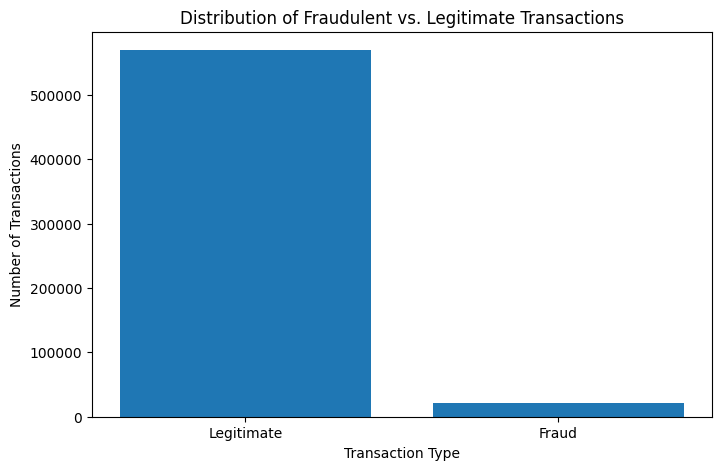

In [ ]:
# Plot the number of legitimate vs. fraudulent transactions

fraud_counts = label.value_counts().sort_index()

plt.figure(figsize=(8, 5))

plt.bar(
    ["Legitimate", "Fraud"],
    fraud_counts.values
)

plt.title("Distribution of Fraudulent vs. Legitimate Transactions")
plt.xlabel("Transaction Type")
plt.ylabel("Number of Transactions")
plt.show()

The dataset contains 569,877 legitimate transactions (96.50%) and 20,663 fraudulent transactions (3.50%). This indicates a significant class imbalance, with fraudulent transactions representing only a small proportion of the overall dataset. This is an important consideration when evaluating the unsupervised anomaly detection models, as their effectiveness will depend on their ability to identify these relatively rare fraudulent transactions.

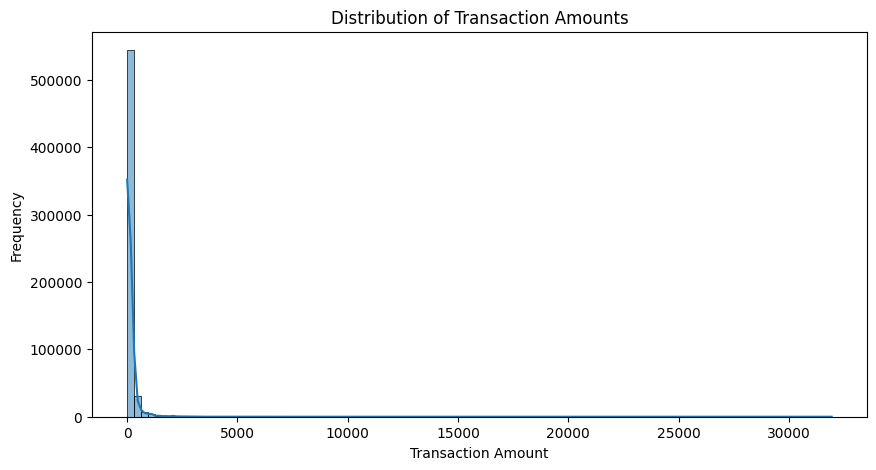

In [ ]:
# Plot the distribution of transaction amounts

plt.figure(figsize=(10, 5))

sns.histplot(
    data=features,
    x="TransactionAmt",
    bins=100,
    kde=True
)

plt.title("Distribution of Transaction Amounts")
plt.xlabel("Transaction Amount")
plt.ylabel("Frequency")
plt.show()

In [ ]:
# Summary statistics for transaction amounts

print(features["TransactionAmt"].describe())

count    590540.000000
mean        135.027176
std         239.162522
min           0.251000
25%          43.321000
50%          68.769000
75%         125.000000
max       31937.391000
Name: TransactionAmt, dtype: float64


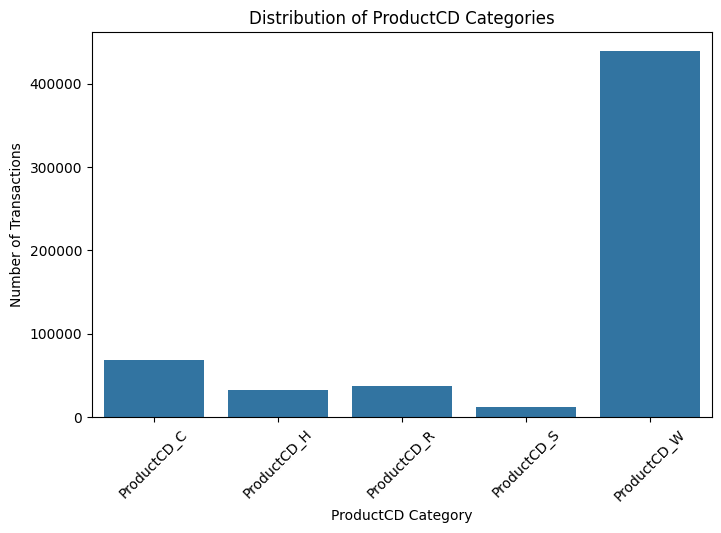

In [ ]:
# Plot the distribution of ProductCD categories

product_counts = features.filter(regex=r'^ProductCD_').sum()

plt.figure(figsize=(8, 5))
sns.barplot(x=product_counts.index, y=product_counts.values)

plt.title("Distribution of ProductCD Categories")
plt.xlabel("ProductCD Category")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=45)
plt.show()

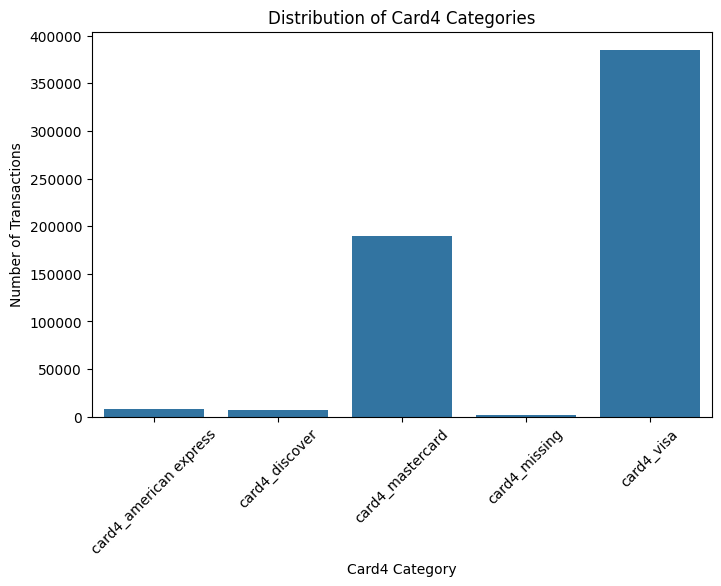

In [ ]:
# Plot the distribution of card4 categories

card4_counts = features.filter(regex=r'^card4_').sum()

plt.figure(figsize=(8, 5))
sns.barplot(x=card4_counts.index, y=card4_counts.values)

plt.title("Distribution of Card4 Categories")
plt.xlabel("Card4 Category")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=45)
plt.show()

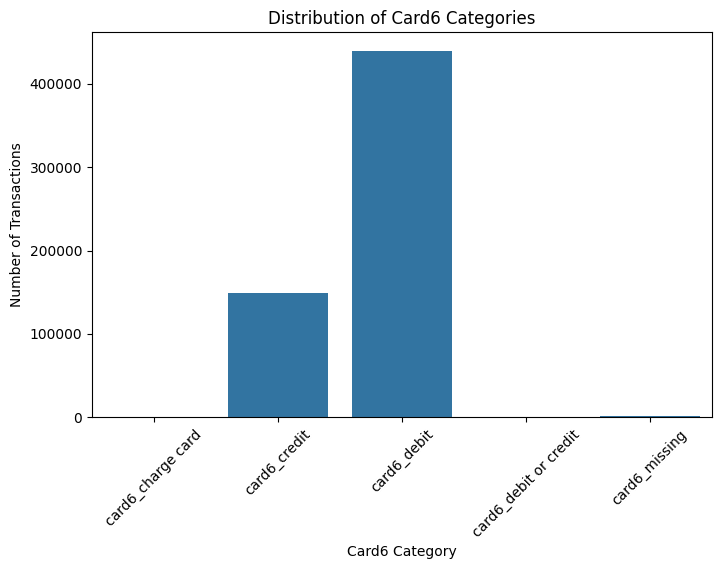

In [ ]:
# Plot the distribution of card6 categories

card6_counts = features.filter(regex=r'^card6_').sum()

plt.figure(figsize=(8, 5))
sns.barplot(x=card6_counts.index, y=card6_counts.values)

plt.title("Distribution of Card6 Categories")
plt.xlabel("Card6 Category")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=45)
plt.show()

The exploratory analysis reveals that key numerical features like `TransactionAmt` are extremely right-skewed, spanning from \$0.25 to over \$31,937 with a median of \$68.77. This severe skewness and wide scale difference, coupled with highly unbalanced categorical features (where `ProductCD_W`, `card4_visa`, and `card6_debit` dominate the volume), indicate that data scaling and transformation will be crucial before applying distance-based anomaly detection methods to prevent high-value transactions from disproportionately biasing the models.

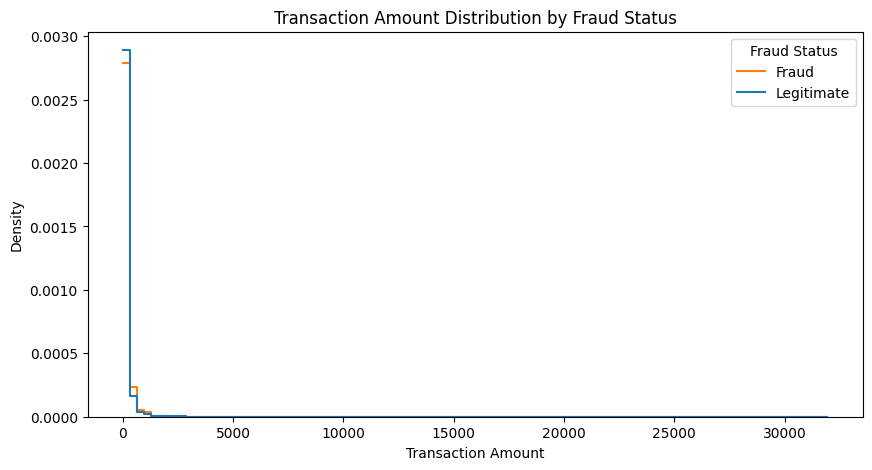

In [ ]:
# Compare transaction amounts for fraudulent vs. legitimate transactions

plot_data = features[['TransactionAmt']].copy()
plot_data['isFraud'] = label.to_numpy()

plt.figure(figsize=(10, 5))

sns.histplot(
    data=plot_data,
    x='TransactionAmt',
    hue='isFraud',
    bins=100,
    stat='density',
    common_norm=False,
    element='step',
    fill=False
)

plt.title("Transaction Amount Distribution by Fraud Status")
plt.xlabel("Transaction Amount")
plt.ylabel("Density")
plt.legend(title="Fraud Status", labels=["Fraud", "Legitimate"])
plt.show()

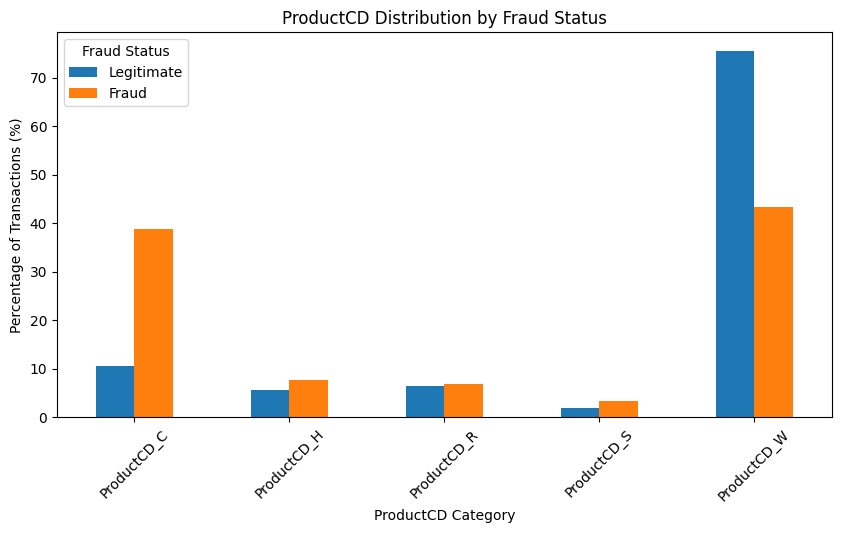

In [ ]:
# Compare ProductCD categories by fraud status

product_cols = features.filter(regex=r'^ProductCD_').columns

product_comparison = features[product_cols].copy()
product_comparison['isFraud'] = label.to_numpy()

product_rates = product_comparison.groupby('isFraud')[product_cols].mean().T * 100

product_rates.plot(kind='bar', figsize=(10, 5))

plt.title("ProductCD Distribution by Fraud Status")
plt.xlabel("ProductCD Category")
plt.ylabel("Percentage of Transactions (%)")
plt.xticks(rotation=45)
plt.legend(["Legitimate", "Fraud"], title="Fraud Status")
plt.show()

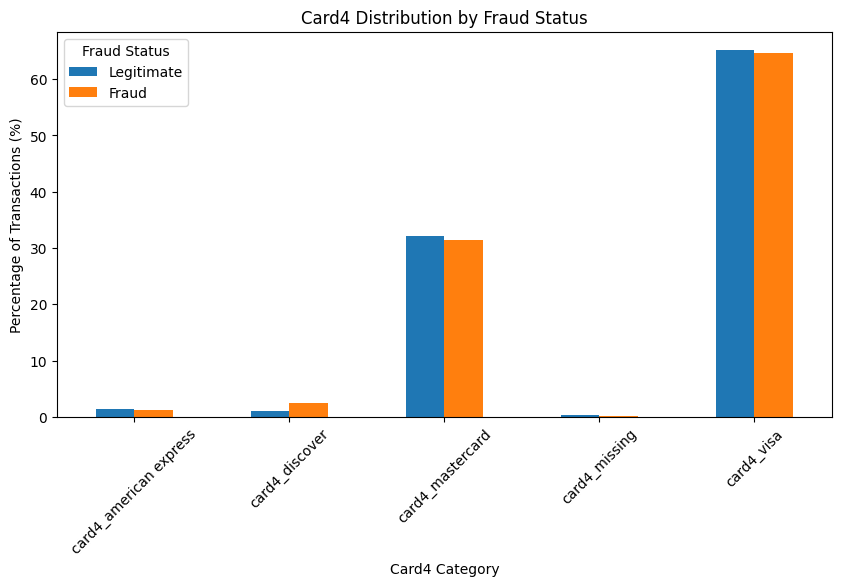

In [ ]:
# Compare card4 categories by fraud status

card4_cols = features.filter(regex=r'^card4_').columns

card4_comparison = features[card4_cols].copy()
card4_comparison['isFraud'] = label.to_numpy()

card4_rates = card4_comparison.groupby('isFraud')[card4_cols].mean().T * 100

card4_rates.plot(kind='bar', figsize=(10, 5))

plt.title("Card4 Distribution by Fraud Status")
plt.xlabel("Card4 Category")
plt.ylabel("Percentage of Transactions (%)")
plt.xticks(rotation=45)
plt.legend(["Legitimate", "Fraud"], title="Fraud Status")
plt.show()

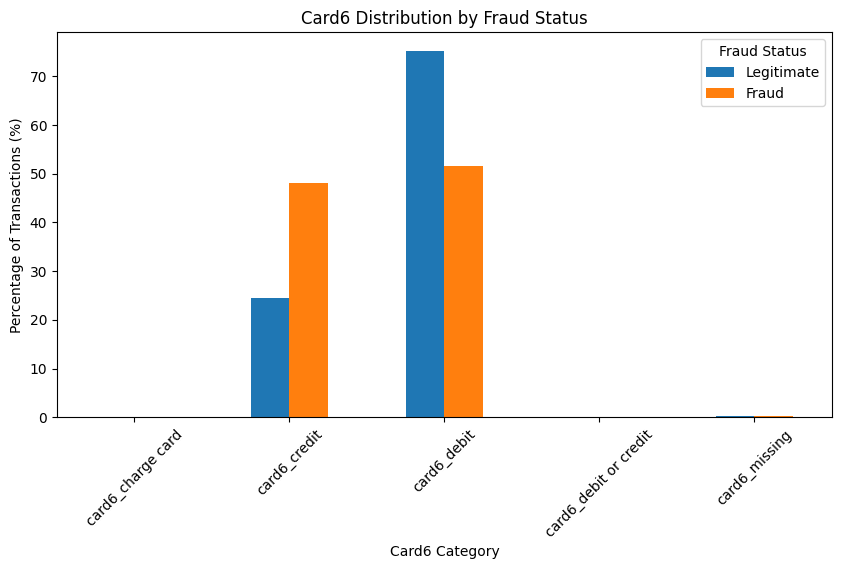

In [38]:
# Compare card6 categories by fraud status

card6_cols = features.filter(regex=r'^card6_').columns

card6_comparison = features[card6_cols].copy()
card6_comparison['isFraud'] = label.to_numpy()

card6_rates = card6_comparison.groupby('isFraud')[card6_cols].mean().T * 100

card6_rates.plot(kind='bar', figsize=(10, 5))

plt.title("Card6 Distribution by Fraud Status")
plt.xlabel("Card6 Category")
plt.ylabel("Percentage of Transactions (%)")
plt.xticks(rotation=45)
plt.legend(["Legitimate", "Fraud"], title="Fraud Status")
plt.show()

The bivariate analysis of categorical features shows that legitimate and fraudulent transactions have highly distinct distributions. For product categories, ProductCD_W accounts for 75.58% of legitimate transactions but only 43.41% of fraudulent ones, whereas ProductCD_C accounts for only 10.62% of legitimate transactions but leaps to 38.76% of fraudulent ones. For card categories, card6_debit accounts for 75.33% of legitimate transactions and 51.66% of fraudulent ones, while card6_credit accounts for only 24.40% of legitimate transactions but rises to 48.15% of fraudulent ones. Meanwhile, card4 categories show nearly identical percentage splits between legitimate and fraudulent groups, indicating that card network names do not vary significantly by fraud status.

In [41]:
# Prepare transaction time data

time_data = pd.DataFrame({
    'TransactionDT': features['TransactionDT'].to_numpy(),
    'isFraud': label['isFraud'].to_numpy()
})

# Convert TransactionDT from seconds into days
time_data['Day'] = (time_data['TransactionDT'] // 86400).astype(int)

# Group transactions by day
daily_data = time_data.groupby('Day').agg(
    Transaction_Count=('isFraud', 'count'),
    Fraud_Rate=('isFraud', 'mean')
)

# Convert fraud rate into percentage
daily_data['Fraud_Rate'] = daily_data['Fraud_Rate'] * 100

print(daily_data.head())

     Transaction_Count  Fraud_Rate
Day                               
1                 5122    2.186646
2                 3730    3.297587
3                 3241    2.838630
4                 4036    2.849356
5                 3964    3.203835


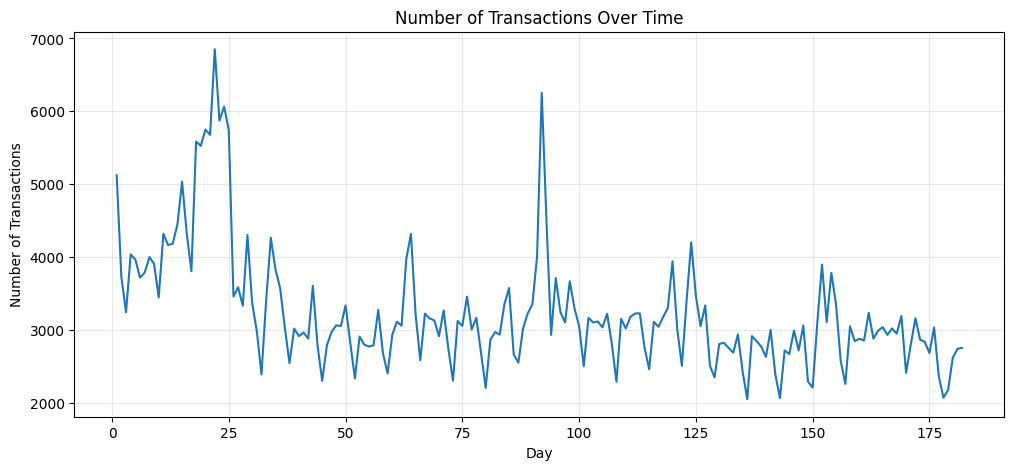

In [42]:
# Plot transaction volume over time

plt.figure(figsize=(12, 5))

plt.plot(
    daily_data.index,
    daily_data['Transaction_Count']
)

plt.title("Number of Transactions Over Time")
plt.xlabel("Day")
plt.ylabel("Number of Transactions")
plt.grid(alpha=0.3)
plt.show()

The transaction volume plot demonstrates that daily transactions start above 5,100, peak sharply near 7,000 transactions around Day 22, experience a second high spike of over 6,200 on Day 92, and otherwise stabilize between 2,000 and 4,000 daily transactions. This establishes a highly dynamic baseline for our daily network traffic.

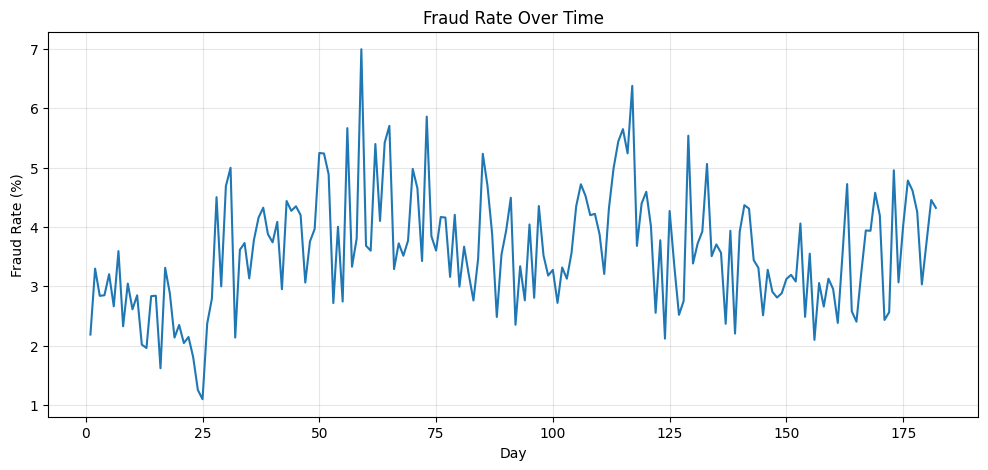

In [43]:
# Plot fraud rate over time

plt.figure(figsize=(12, 5))

plt.plot(
    daily_data.index,
    daily_data['Fraud_Rate']
)

plt.title("Fraud Rate Over Time")
plt.xlabel("Day")
plt.ylabel("Fraud Rate (%)")
plt.grid(alpha=0.3)
plt.show()

The temporal analysis over the 182-day window demonstrates that daily transaction counts and fraud rates fluctuate independently. Daily transaction counts start above 5,100, peak sharply near 7,000 transactions around Day 22, experience a second high spike of over 6,200 on Day 92, and otherwise stabilize between 2,000 and 4,000 daily transactions. In contrast, the daily fraud rate begins near 2.19% on Day 1, reaches a low point near 1.1% on Day 25, and then exhibits high volatility with frequent spikes of 5% to 6%, peaking at 7.00% on Day 59. This visual divergence indicates that periods of higher transaction volumes do not correlate directly with higher fraud rates.

In [44]:
# Create transaction amount ranges

# Extract fraud labels as a 1D Series
fraud_label = label.squeeze()

# Combine transaction amounts and fraud labels
amount_data = pd.DataFrame({
    'TransactionAmt': features['TransactionAmt'].to_numpy(),
    'isFraud': fraud_label.to_numpy()
})

# Define transaction amount ranges
bins = [0, 10, 50, 200, 500, float('inf')]
bin_labels = ['$0-$10', '$10-$50', '$50-$200', '$200-$500', '$500+']

# Assign each transaction to an amount bucket
amount_data['Amount_Bucket'] = pd.cut(
    amount_data['TransactionAmt'],
    bins=bins,
    labels=bin_labels,
    include_lowest=True
)

# Calculate fraud rate and transaction count per bucket
amount_summary = amount_data.groupby('Amount_Bucket', observed=False).agg(
    Transaction_Count=('isFraud', 'count'),
    Fraud_Rate=('isFraud', 'mean')
)

# Convert fraud rate to percentage
amount_summary['Fraud_Rate'] *= 100

print(amount_summary)

               Transaction_Count  Fraud_Rate
Amount_Bucket                               
$0-$10                      7829    7.765998
$10-$50                   196695    3.673200
$50-$200                  292136    2.973615
$200-$500                  71001    4.415431
$500+                      22879    4.405787


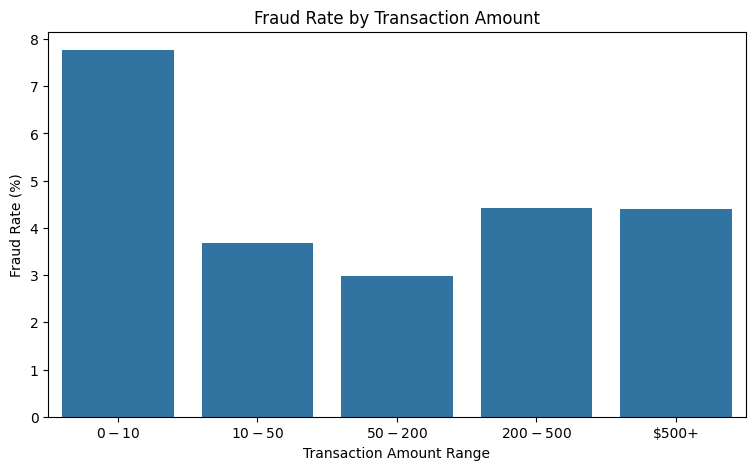

In [45]:
# Plot fraud rate by transaction amount

plt.figure(figsize=(9, 5))

sns.barplot(
    x=amount_summary.index.astype(str),
    y=amount_summary['Fraud_Rate']
)

plt.title("Fraud Rate by Transaction Amount")
plt.xlabel("Transaction Amount Range")
plt.ylabel("Fraud Rate (%)")
plt.show()

Grouping the transaction values into designated brackets reveals a non-linear pattern in risk across different amounts. Transactions under 10 show the highest overall fraud rate at 7.77% across 7,829 transactions. This rate drops down to 3.67% for transactions between 10 and 50, and falls further to its lowest level of 2.97% for standard purchases between 50 and 200. Beyond this threshold, the fraud rate climbs back up to 4.42% for transactions in the 200 to 500 range, and remains highly similar at 4.41% for high-value transactions of 500 or more.

In [46]:
# Identify columns representing missing information

missing_cols = [
    col for col in features.columns
    if 'missing' in col.lower()
]

print("Missing indicator columns:")
print(missing_cols)

Missing indicator columns:
['card2_missing', 'card3_missing', 'card4_missing', 'card5_missing', 'card6_missing', 'addr1_missing', 'addr2_missing', 'P_emaildomain_missing', 'R_emaildomain_missing', 'M1_missing', 'M2_missing', 'M3_missing', 'M4_missing', 'M5_missing', 'M6_missing', 'M7_missing', 'M8_missing', 'M9_missing', 'id_12_missing', 'id_15_missing', 'id_16_missing', 'id_28_missing', 'id_29_missing', 'id_30_missing', 'id_31_missing', 'id_33_missing', 'id_34_missing', 'id_35_missing', 'id_36_missing', 'id_37_missing', 'id_38_missing', 'DeviceType_missing', 'DeviceInfo_missing']


In [47]:
# Compare fraud rates based on missing DeviceInfo

fraud_label = label.squeeze()

device_data = pd.DataFrame({
    'DeviceInfo_missing': features['DeviceInfo_missing'].to_numpy(),
    'isFraud': fraud_label.to_numpy()
})

# Calculate transaction counts and fraud rates
device_summary = device_data.groupby('DeviceInfo_missing').agg(
    Transaction_Count=('isFraud', 'count'),
    Fraud_Rate=('isFraud', 'mean')
)

device_summary['Fraud_Rate'] *= 100

device_summary.index = ['Available', 'Missing']

print(device_summary)

           Transaction_Count  Fraud_Rate
Available             118666    7.253131
Missing               471874    2.554919


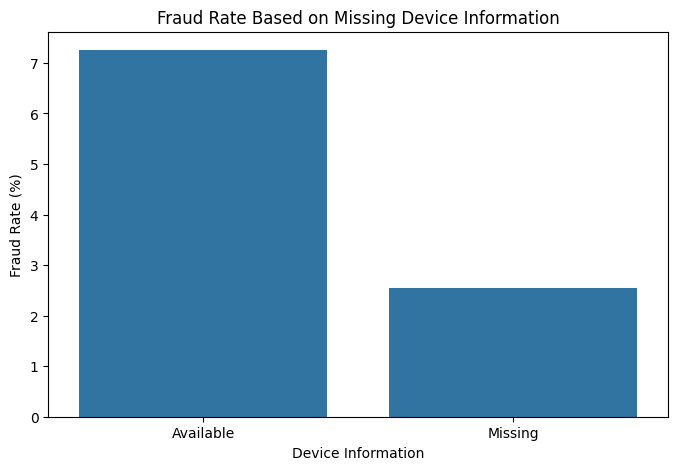

In [48]:
# Plot fraud rate based on missing DeviceInfo

plt.figure(figsize=(8, 5))

sns.barplot(
    x=device_summary.index,
    y=device_summary['Fraud_Rate']
)

plt.title("Fraud Rate Based on Missing Device Information")
plt.xlabel("Device Information")
plt.ylabel("Fraud Rate (%)")
plt.show()

Analyzing the dataset reveals that there are 118,666 transactions with available device information, which exhibit a fraud rate of 7.25%. In contrast, there are 471,874 transactions where device information is missing, resulting in a significantly lower fraud rate of 2.55%. This shows that transactions with available device details are nearly three times more likely to be fraudulent compared to those where the device details are missing.

In [51]:
# Identify features that differ most between fraud and legitimate transactions

fraud_label = label.squeeze()

# Separate features by fraud status
legitimate = features[fraud_label.to_numpy() == 0]
fraudulent = features[fraud_label.to_numpy() == 1]

# Calculate mean and standard deviation for each group
legitimate_mean = legitimate.mean()
fraudulent_mean = fraudulent.mean()

legitimate_std = legitimate.std()
fraudulent_std = fraudulent.std()

# Calculate pooled standard deviation
pooled_std = np.sqrt(
    (legitimate_std**2 + fraudulent_std**2) / 2
)

# Calculate standardized mean difference
differences = (
    (fraudulent_mean - legitimate_mean).abs() / pooled_std
)

# Remove features with undefined differences
differences = differences.replace([np.inf, -np.inf], np.nan).dropna()

# Select the top 3 features
top_features = differences.sort_values(ascending=False).head(3)

print("Top 3 features with the largest differences:")
print(top_features)

print("\nComparison of group means:")
print(pd.DataFrame({
    'Legitimate Mean': legitimate_mean[top_features.index],
    'Fraud Mean': fraudulent_mean[top_features.index],
    'Standardized Difference': top_features
}))

Top 3 features with the largest differences:
R_emaildomain_missing    0.702592
addr2_87.0               0.701643
ProductCD_W               0.69364
dtype: Float64

Comparison of group means:
                       Legitimate Mean  Fraud Mean  Standardized Difference
R_emaildomain_missing         0.778787    0.456662                 0.702592
addr2_87.0                    0.891427    0.603833                 0.701643
ProductCD_W                   0.755779    0.434061                  0.69364


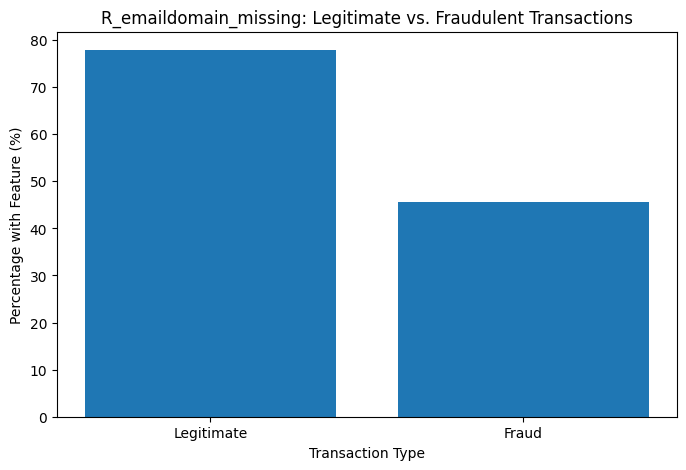

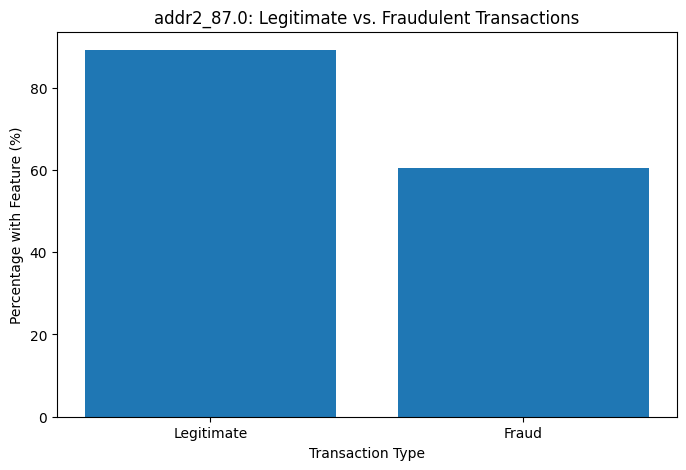

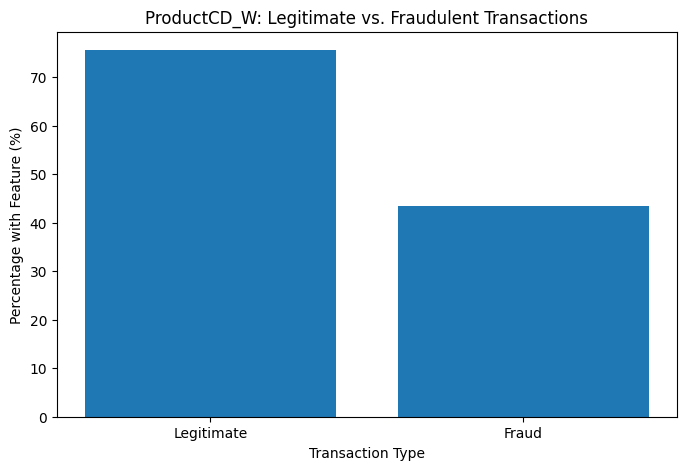

In [52]:
# Visualize the top 3 features

for feature in top_features.index:

    plt.figure(figsize=(8, 5))

    # Check whether the feature is binary (one-hot encoded)
    if features[feature].nunique() <= 2:

        comparison = pd.DataFrame({
            'Feature': features[feature].to_numpy(),
            'isFraud': fraud_label.to_numpy()
        })

        rates = comparison.groupby('isFraud')['Feature'].mean() * 100

        plt.bar(
            ['Legitimate', 'Fraud'],
            rates.values
        )

        plt.ylabel("Percentage with Feature (%)")

    else:
        # Boxplot for continuous numerical features
        plot_data = pd.DataFrame({
            feature: features[feature].to_numpy(),
            'isFraud': fraud_label.to_numpy()
        })

        sns.boxplot(
            data=plot_data,
            x='isFraud',
            y=feature,
            showfliers=False
        )

        plt.xticks([0, 1], ['Legitimate', 'Fraud'])
        plt.ylabel(feature)

    plt.title(f"{feature}: Legitimate vs. Fraudulent Transactions")
    plt.xlabel("Transaction Type")
    plt.show()

Analyzing the features with the largest standardized differences between the two classes reveals key behavioral variations. For `R_emaildomain_missing`, the indicator is present in 77.88% of legitimate transactions but drops to 45.67% in fraudulent transactions. Similarly, the local geographic marker `addr2_87.0` is present in 89.14% of legitimate transactions but only in 60.38% of fraudulent ones. Lastly, the product category `ProductCD_W` represents 75.58% of legitimate purchases while representing only 43.41% of fraudulent activity. These metrics show that fraudulent transactions are significantly less likely to have missing purchaser email domains, much less likely to originate from geographic region 87.0, and far less likely to be associated with product category W.

In [53]:
# Select all V-features
v_features = features.filter(regex=r'^V\d+$')

print("Number of V-features:", v_features.shape[1])

# Calculate correlations using a sample of 50,000 transactions
# This reduces computation time while providing a useful overview
v_sample = v_features.sample(
    n=min(50000, len(v_features)),
    random_state=42
)

correlation_matrix = v_sample.corr()

print("Correlation matrix shape:", correlation_matrix.shape)

Number of V-features: 339
Correlation matrix shape: (339, 339)


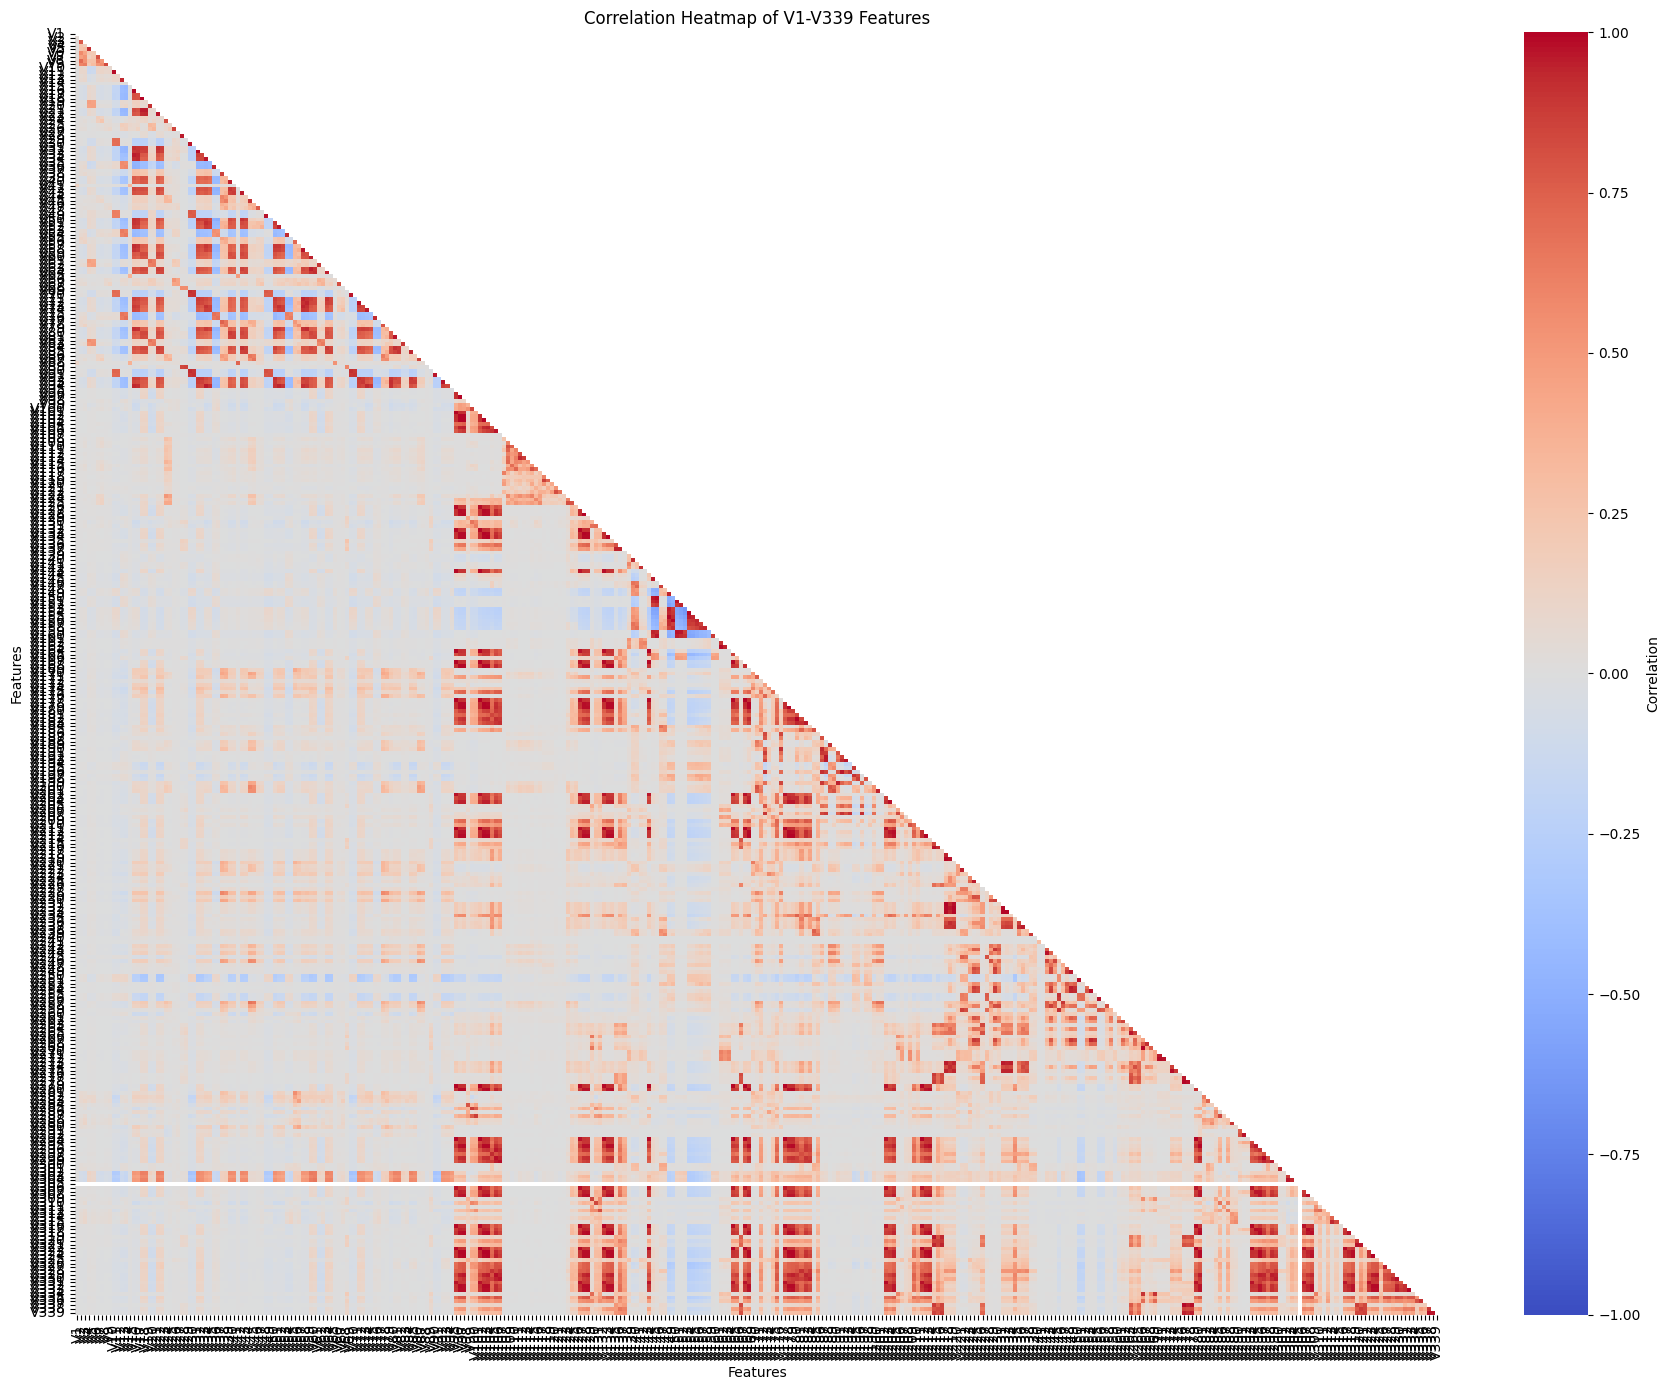

In [54]:
# Plot correlation heatmap

plt.figure(figsize=(18, 14))

# Create mask to hide the upper triangle
mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))

sns.heatmap(
    correlation_matrix,
    mask=mask,
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    center=0,
    xticklabels=True,
    yticklabels=True,
    cbar_kws={'label': 'Correlation'}
)

plt.title("Correlation Heatmap of V1-V339 Features")
plt.xlabel("Features")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

In [55]:
# Identify the most highly correlated feature pairs

upper_triangle = correlation_matrix.where(
    np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
)

correlation_pairs = upper_triangle.stack().reset_index()

correlation_pairs.columns = [
    'Feature 1',
    'Feature 2',
    'Correlation'
]

# Sort by absolute correlation
correlation_pairs['Absolute Correlation'] = (
    correlation_pairs['Correlation'].abs()
)

top_correlations = correlation_pairs.sort_values(
    by='Absolute Correlation',
    ascending=False
).head(15)

print(top_correlations)

      Feature 1 Feature 2  Correlation  Absolute Correlation
27312       V95      V101     0.999650              0.999650
55196      V279      V293     0.999635              0.999635
27532       V95      V322     0.999519              0.999519
28969      V101      V322     0.999491              0.999491
42256      V167      V177     0.999471              0.999471
28941      V101      V293     0.999227              0.999227
27490       V95      V279     0.999077              0.999077
27797       V97      V103     0.998958              0.998958
27504       V95      V293     0.998869              0.998869
55256      V280      V295     0.998861              0.998861
55945      V293      V322     0.998835              0.998835
28927      V101      V279     0.998834              0.998834
55224      V279      V322     0.998783              0.998783
29442      V103      V324     0.998774              0.998774
28017       V97      V324     0.998695              0.998695


Analyzing the correlation structure among the 339 V-features reveals an extreme degree of redundancy. The correlation matrix shows many tight, highly correlated clusters, with the top fifteen feature pairs all exhibiting absolute Pearson correlation coefficients above 0.998. Specifically, the pairs V95/V101 and V279/V293 have nearly perfect linear relationships with correlations of 0.99965 and 0.99963, respectively, and pairs such as V95/V322 and V101/V322 show correlation coefficients of 0.99951 and 0.99949. This extensive multicollinearity indicates that the V-features contain vast amounts of redundant information.

In [56]:
# Identify highly correlated features (absolute correlation > 0.95)

threshold = 0.95

# Start with an empty list of features to keep
features_to_keep = []
features_to_drop = []

# Check each feature against previously retained features
for feature in correlation_matrix.columns:

    if not features_to_keep:
        features_to_keep.append(feature)
        continue

    correlations = correlation_matrix.loc[
        feature, features_to_keep
    ].abs()

    if (correlations > threshold).any():
        features_to_drop.append(feature)
    else:
        features_to_keep.append(feature)

print("Number of V-features originally:", len(correlation_matrix.columns))
print("Number of features to remove:", len(features_to_drop))
print("Number of features to retain:", len(features_to_keep))

print("\nFeatures to remove:")
print(features_to_drop)

Number of V-features originally: 339
Number of features to remove: 100
Number of features to retain: 239

Features to remove:
['V11', 'V16', 'V18', 'V21', 'V28', 'V30', 'V32', 'V33', 'V40', 'V43', 'V49', 'V52', 'V58', 'V60', 'V70', 'V72', 'V74', 'V81', 'V91', 'V93', 'V97', 'V101', 'V102', 'V103', 'V106', 'V126', 'V127', 'V128', 'V132', 'V133', 'V134', 'V143', 'V145', 'V150', 'V154', 'V155', 'V156', 'V159', 'V163', 'V164', 'V167', 'V168', 'V177', 'V178', 'V179', 'V182', 'V192', 'V193', 'V196', 'V199', 'V202', 'V204', 'V211', 'V212', 'V213', 'V216', 'V219', 'V225', 'V231', 'V232', 'V233', 'V237', 'V244', 'V249', 'V251', 'V253', 'V256', 'V265', 'V269', 'V271', 'V272', 'V273', 'V277', 'V278', 'V279', 'V280', 'V292', 'V293', 'V295', 'V296', 'V298', 'V299', 'V304', 'V306', 'V307', 'V308', 'V316', 'V317', 'V318', 'V319', 'V321', 'V322', 'V323', 'V324', 'V329', 'V331', 'V332', 'V333', 'V337', 'V339']


In [57]:
# Remove highly correlated V-features

v_features_reduced = v_features.drop(columns=features_to_drop)

print("Original V-features:", v_features.shape)
print("Reduced V-features:", v_features_reduced.shape)

Original V-features: (590540, 339)
Reduced V-features: (590540, 239)


To address potential redundancy among the V-features, we recommend removing one feature from pairs with an absolute correlation greater than 0.95. This threshold identifies highly correlated features that may contain overlapping information. A consistent feature-selection approach will be applied to both the Isolation Forest and LOF models to ensure comparability between their results. The retained features will be selected using the same correlation-based procedure, with the remaining feature redundancy acknowledged as a potential limitation.

In [58]:
# Calculate percentage of V-features correlated above 0.95

threshold = 0.95

# Get absolute correlations
abs_corr = correlation_matrix.abs()

# Remove correlations of features with themselves
np.fill_diagonal(abs_corr.values, 0)

# Identify features with at least one correlation above 0.95
highly_correlated = (abs_corr > threshold).any(axis=0)

# Calculate percentage
correlated_count = highly_correlated.sum()
total_features = len(correlation_matrix.columns)

percentage = (correlated_count / total_features) * 100

print(f"Total V-features: {total_features}")
print(f"Highly correlated V-features: {correlated_count}")
print(f"Percentage of highly correlated V-features: {percentage:.2f}%")

Total V-features: 339
Highly correlated V-features: 158
Percentage of highly correlated V-features: 46.61%


Approximately 47% of the V-features exhibit an absolute correlation greater than 0.95 with at least one other V-feature, indicating substantial redundancy within the dataset. This supports considering correlation-based feature selection during preprocessing to reduce overlapping information before applying anomaly detection models.

In [7]:
import pyarrow.parquet as pq

feature_file = pq.ParquetFile(features_path)
label_file = pq.ParquetFile(label_path)

features_sample = next(
    feature_file.iter_batches(batch_size=5000)
).to_pandas()

label_sample = next(
    label_file.iter_batches(batch_size=5000)
).to_pandas()['isFraud']

print("Features sample shape:", features_sample.shape)
print("Label sample shape:", label_sample.shape)

Features sample shape: (5000, 652)
Label sample shape: (5000,)


In [8]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Convert features to float32 to reduce memory usage
X = features_sample.to_numpy(dtype=np.float32)

# Standardize features
scaler = StandardScaler()
scaled_features = scaler.fit_transform(X)

# Reduce to 2 dimensions
pca = PCA(
    n_components=2,
    svd_solver='randomized',
    random_state=42
)

reduced_features = pca.fit_transform(scaled_features)

# Store results
reduced_features = pd.DataFrame(
    reduced_features,
    columns=['PC1', 'PC2']
)

print("Reduced features shape:", reduced_features.shape)

print(
    "Total variance explained:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

Reduced features shape: (5000, 2)
Total variance explained: 15.15 %


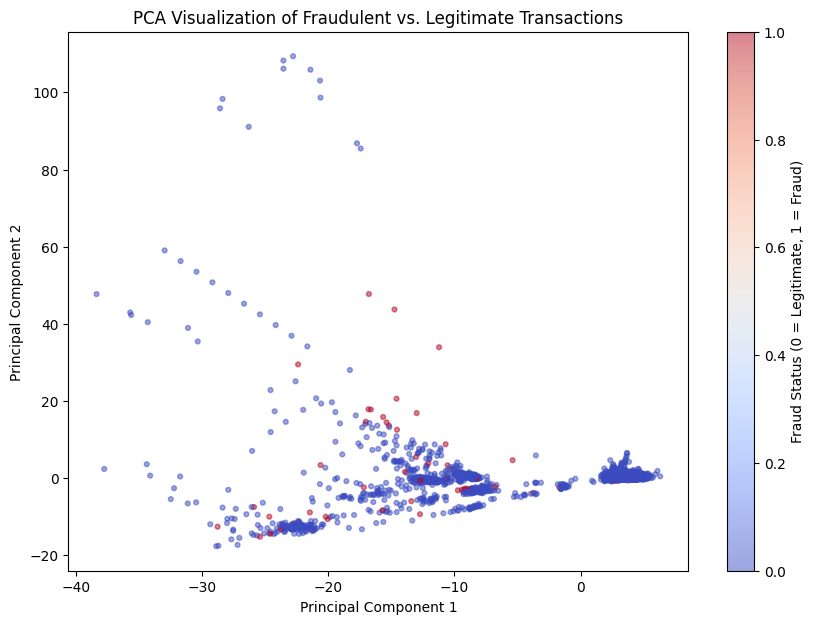

In [9]:
# Create a 2D PCA scatterplot

plt.figure(figsize=(10, 7))

plt.scatter(
    reduced_features.loc[label_sample.index, 'PC1']
    if reduced_features.index.equals(label_sample.index)
    else reduced_features['PC1'],
    reduced_features['PC2'],
    c=label_sample.to_numpy(),
    cmap='coolwarm',
    alpha=0.5,
    s=12
)

plt.title("PCA Visualization of Fraudulent vs. Legitimate Transactions")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(label="Fraud Status (0 = Legitimate, 1 = Fraud)")
plt.show()

PCA was used to reduce the 652 original features to two principal components using a sample of 5,000 transactions. The two components explain 15.15% of the total variance in the sampled data. Although this represents a relatively small proportion of the original variation, the dimensionality reduction provides a simplified two-dimensional representation for visualizing potential patterns and differences between fraudulent and legitimate transactions. The visualization is based on a sample rather than the full dataset due to memory limitations.

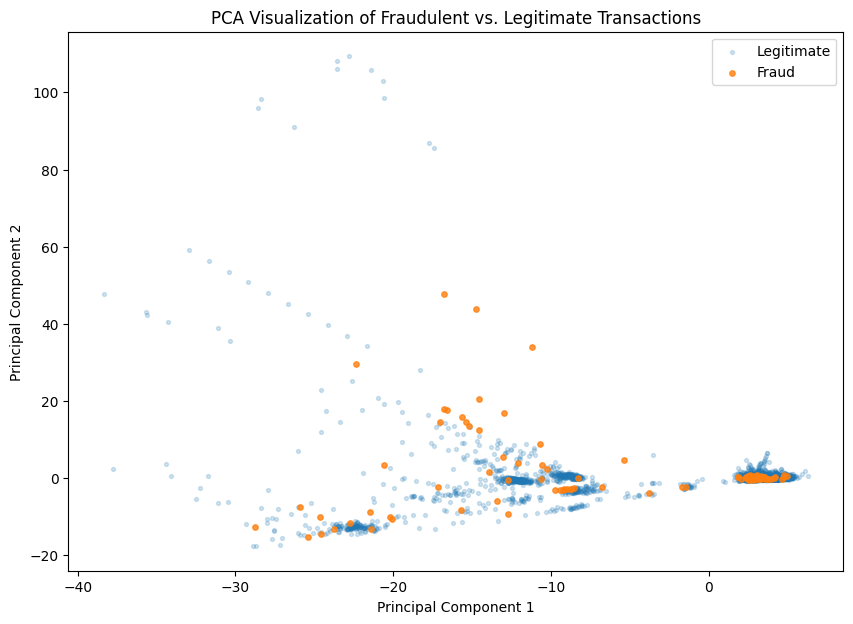

In [10]:
# Identify fraud and legitimate transactions
fraud_mask = label_sample.to_numpy() == 1

# Create scatterplot
plt.figure(figsize=(10, 7))

# Plot legitimate transactions
plt.scatter(
    reduced_features.loc[~fraud_mask, 'PC1'],
    reduced_features.loc[~fraud_mask, 'PC2'],
    label='Legitimate',
    alpha=0.2,
    s=8
)

# Plot fraudulent transactions
plt.scatter(
    reduced_features.loc[fraud_mask, 'PC1'],
    reduced_features.loc[fraud_mask, 'PC2'],
    label='Fraud',
    alpha=0.8,
    s=15
)

plt.title('PCA Visualization of Fraudulent vs. Legitimate Transactions')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend()
plt.show()

The 2D PCA visualization of the 5,000 transaction sample shows that legitimate and fraudulent transactions heavily overlap, though some geometric differences appear. Legitimate transactions are highly concentrated in a dense cluster on the right side of the plot where Principal Component 1 is positive. Fraudulent transactions are more widely dispersed and sparser, appearing across the outer structures on the left and upper areas where Principal Component 1 is negative, although they still overlap significantly with the legitimate transactions. However, note that this visualization uses only 5,000 transactions therefore, it provides an initial visual exploration, not definitive evidence of whether fraud can be detected.